# Apache SpamAssassin Spam Classifier

In [2]:
from pathlib import Path
import splitfolders
import pandas as pd
import sklearn
import tarfile
import shutil
import os
import re
import random

In [3]:
seed = 42
RAW_DATA_DIR = Path('./../raw_data')

## Data download and Inspection

The following script will download the dataset corpus to data/spam_assassin_corpus

In [4]:
!rm -r {RAW_DATA_DIR}
!wget -r -q -np -nd \
    -P {RAW_DATA_DIR}/spam_assassin_corpus \
    -A "*.bz2,readme.html" \
    -X /old/publiccorpus/obsolete/ \
    https://spamassassin.apache.org/old/publiccorpus/

Now that the data is downloaded, we will need to unzip it.

In [ ]:
for filename in os.listdir(f'{RAW_DATA_DIR}/spam_assassin_corpus'):
    if filename.endswith('.tar.bz2'):
        with tarfile.open(f'{RAW_DATA_DIR}/spam_assassin_corpus/{filename}', 'r:bz2') as f:
            f.extractall(f'{RAW_DATA_DIR}/{filename[:-8]}')

for parent_dir in RAW_DATA_DIR.iterdir():
    if not parent_dir.is_dir():
        continue

    # get subfolders in the parent dir
    child_dirs = [d for d in parent_dir.iterdir() if d.is_dir()]

    if not child_dirs:
        continue

    # for each child dir, move the files to the parent dir
    for child_dir in child_dirs:
        for file in child_dir.iterdir():
            if file.name == "cmds":
                continue
            shutil.move(str(file), str(parent_dir))

        if not any(child_dir.iterdir()):
            child_dir.rmdir()
        else:
            shutil.rmtree(child_dir)

# take out the readme.html file from the spam_assassin_corpus folder and move it to the data folder
shutil.move(f'{RAW_DATA_DIR}/spam_assassin_corpus/readme.html', f'{RAW_DATA_DIR}/readme.html')    
shutil.rmtree(f'{RAW_DATA_DIR}/spam_assassin_corpus')

/var/folders/cl/gj5wytzj6ns_nk7qgjq7v7q40000gn/T/ipykernel_15833/1480270791.py:4: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  f.extractall(f'{RAW_DATA_DIR}/{filename[:-8]}')


Let's inspect a ham email and a spam email

In [6]:
def inspect_file(folder_name, file_type):
    sample_filename = os.listdir(RAW_DATA_DIR / folder_name)[0]
    sample_file = RAW_DATA_DIR / folder_name / sample_filename
    with open(sample_file, 'r', encoding='latin-1') as f:
        text = f.read()
    print(f"Sample {file_type}: {sample_filename}\n")
    print(text)

In [7]:
inspect_file('20030228_hard_ham', 'ham')

Sample ham: 00113.1d37bdbcad4975b5012cc6d87a048ecf

Return-Path: <bounce-lghtml-2534368@sprocket.lockergnome.com>
Received: from lockergnome.com (sprocket.lockergnome.com [130.94.96.247])
	by dogma.slashnull.org (8.11.6/8.11.6) with SMTP id g6IKksJ07017
	for <qqqqqqqqqq-lg@spamassassin.taint.org>; Thu, 18 Jul 2002 21:46:54 +0100
X-Mailer: ListManager Web Interface
Date: Thu, 18 Jul 2002 09:55:22 -0500
Subject: [Lockergnome Windows Daily]  Sticker Courtesy
To: qqqqqqqqqq-lg@spamassassin.taint.org
From: Lockergnome Windows Daily <subscriptions@lockergnome.com>
List-Unsubscribe: <mailto:leave-lghtml-2534368N@sprocket.lockergnome.com>
List-Subscribe: <mailto:subscribe-lghtml@sprocket.lockergnome.com>
List-Owner: <mailto:owner-lghtml@sprocket.lockergnome.com>
X-URL: <http://www.lockergnome.com/>
X-List-Host: Lockergnome <http://www.lockergnome.com/>
Reply-To: leave-lghtml-2534368N@sprocket.lockergnome.com
Sender: bounce-lghtml-2534368@sprocket.lockergnome.com
Message-Id: <LISTMANAGERSQL-253

In [8]:
folder_name = '20030228_spam'
inspect_file(folder_name, 'spam')

Sample spam: 00249.5f45607c1bffe89f60ba1ec9f878039a

From pamela4701@eudoramail.com  Mon Sep  9 10:51:29 2002
Return-Path: <pamela4701@eudoramail.com>
Delivered-To: zzzz@localhost.spamassassin.taint.org
Received: from localhost (jalapeno [127.0.0.1])
	by zzzzason.org (Postfix) with ESMTP id 5D14216F17
	for <zzzz@localhost>; Mon,  9 Sep 2002 10:49:04 +0100 (IST)
Received: from jalapeno [127.0.0.1]
	by localhost with IMAP (fetchmail-5.9.0)
	for zzzz@localhost (single-drop); Mon, 09 Sep 2002 10:49:04 +0100 (IST)
Received: from smtp-ft1.fr.colt.net (smtp-ft1.fr.colt.net [213.41.78.25])
    by dogma.slashnull.org (8.11.6/8.11.6) with ESMTP id g899AfC06863 for
    <webmaster@efi.ie>; Mon, 9 Sep 2002 10:10:41 +0100
Received: from mailsweeper.abc-arbitrage.com (mailhost2.abc-arbitrage.com
    [213.41.18.43]) by smtp-ft1.fr.colt.net with ESMTP id g899AvS20929 for
    <webmaster@efi.ie>; Mon, 9 Sep 2002 11:10:57 +0200
Received: from 210.214.94.76 (unverified) by mailsweeper.abc-arbitrage.com
   

Now that we have seen the email format, we will check how many such files are there.

In [9]:
data_info = pd.DataFrame(columns=['folder', 'type'])
data_info['folder'] = os.listdir(RAW_DATA_DIR)
data_info.drop(data_info[data_info['folder'] == 'readme.html'].index, inplace=True)
data_info['type'] = data_info['folder'].apply(lambda x: 'spam' if 'spam' in x else 'ham')
data_info['files_count_w_duplicates'] = data_info['folder'].apply(lambda x: len(os.listdir(RAW_DATA_DIR / x)))

total_files = data_info['files_count_w_duplicates'].sum()
total_spam_files = data_info[data_info['type'] == 'spam']['files_count_w_duplicates'].sum()
total_ham_files = data_info[data_info['type'] == 'ham']['files_count_w_duplicates'].sum()

data_info

,folder,type,files_count_w_duplicates
0,20030228_easy_ham_2,ham,1400
1,20030228_hard_ham,ham,250
2,20030228_spam,spam,500
4,20030228_easy_ham,ham,2500
5,20030228_spam_2,spam,1397
6,20021010_spam,spam,501
7,20021010_hard_ham,ham,250
8,20021010_easy_ham,ham,2551
9,20050311_spam_2,spam,1396


In [10]:
print(f"Total files: {total_files}")
print(f"Total spam files: {total_spam_files}")
print(f"Total ham files: {total_ham_files}")
print(f"Percentage of spam: {total_spam_files / total_files * 100:.2f}%")

Total files: 10745
Total spam files: 3794
Total ham files: 6951
Percentage of spam: 35.31%


Wow, there is some dataset imbalance. Only 35% of the files are spam

## Data Cleaning

If there is any duplicate email, they will be deleted to avoid data leakage.

In [11]:
seen_emails = set()
removed_duplicates = []
number_of_duplicates = 0

for parent_dir in RAW_DATA_DIR.iterdir():
    if not parent_dir.is_dir():
        continue

    for file in parent_dir.iterdir():
        with open(file, 'r', encoding='latin-1') as f:
            text = f.read()
            if text in seen_emails:
                number_of_duplicates += 1
                removed_duplicates.append(file)
                os.remove(file)
            else:
                seen_emails.add(text)

print(f"Total number of duplicates: {number_of_duplicates}")

Total number of duplicates: 1580


In [12]:
data_info['files_count_wo_duplicates'] = data_info['folder'].apply(lambda x: len(os.listdir(RAW_DATA_DIR / x)))

total_files = data_info['files_count_wo_duplicates'].sum()
total_spam_files = data_info[data_info['type'] == 'spam']['files_count_wo_duplicates'].sum()
total_ham_files = data_info[data_info['type'] == 'ham']['files_count_wo_duplicates'].sum()

data_info

,folder,type,files_count_w_duplicates,files_count_wo_duplicates
0,20030228_easy_ham_2,ham,1400,1400
1,20030228_hard_ham,ham,250,250
2,20030228_spam,spam,500,500
4,20030228_easy_ham,ham,2500,2500
5,20030228_spam_2,spam,1397,1397
6,20021010_spam,spam,501,491
7,20021010_hard_ham,ham,250,217
8,20021010_easy_ham,ham,2551,2410
9,20050311_spam_2,spam,1396,0


In [13]:
print(f"Total files: {total_files}")
print(f"Total spam files: {total_spam_files}")
print(f"Total ham files: {total_ham_files}")
print(f"Percentage of spam: {total_spam_files / total_files * 100:.2f}%")

Total files: 9165
Total spam files: 2388
Total ham files: 6777
Percentage of spam: 26.06%


There is even more imbalance than we thought earlier.

## Train-Test Split

We will use a 80-20 split. For each folder in data, we will do a 80-20 split of the folder. The split will be saved on data_split folder.

In [14]:
DATASPLIT_DIR = Path('./../data_split')
if os.path.exists(f'{DATASPLIT_DIR}'):
    shutil.rmtree(f'{DATASPLIT_DIR}')
splitfolders.ratio(f'{RAW_DATA_DIR}', output=f'{DATASPLIT_DIR}', 
            seed=seed, ratio=(.8, 0.0, 0.20), group_prefix=None, shuffle=True)

In [15]:
def collect_file_paths(file_type):
    res = []
    for folder in Path(DATASPLIT_DIR / file_type).iterdir():
        if folder.is_dir():
            res.extend([f for f in Path(folder).iterdir() if f.is_file()])
    return res

train_files = collect_file_paths('train')
test_files = collect_file_paths('test')

In [16]:

def create_train_test_split(file_list, shuffle = True):
    X = []
    y = []

    if shuffle:
        random.seed(seed)
        random.shuffle(file_list)

    for f in file_list:
        with open(f, 'r', encoding='latin-1') as file:
            text = file.read()
        X.append(text)
        y.append(1 if 'spam' in str(f) else 0)
    return X, y

X_train, y_train = create_train_test_split(train_files)
X_test, y_test = create_train_test_split(test_files)

len(X_train), len(X_test), len(y_train), len(y_test)

(7330, 1835, 7330, 1835)

## Data Preparation Pipeline

The word processing and turning the email into sparse vector should be done here.

We will have to use either FunctionalTransformer or CustomTransformer(BaseEstimator, TransformerMixin) or both class for this step.

Email preprocessing to prevent target leakage:

- remove spam headers - remove email header completely for now, if we have time later we will try to encode the headers
- strip email headers
- convert email to lowercase,
- replace urls with 'URL',
- replace numbers with 'NUMBER',
- trim word endings

The current baseline removes headers by splitting on the first blank line and then lowercasing the body.

We also have a small `email`-module experiment below to inspect `Subject`, `From`, and the message body more reliably.

A more robust MIME-aware preprocessing function is still in progress.

In [ ]:
def clean_emails(emails, remove_headers=True):
    """
        Process the email text by removing headers, converting to lowercase

        BASELINE: remove headers from the emails in X
        ADVANCED: customize the headers
            - remove X-spam or related subheaders
            - replace urls with 'URL'
            - replace numbers with 'NUMBER'
            - trim word endings
    """
    cleaned = []
    for email in emails:
        if remove_headers: # remove headers from the email
            email = email.split('\n\n', 1)[-1]
        else: # advanced customization here for later
            pass

        email = email.lower()
        cleaned.append(email)
    return cleaned

print(clean_emails([X_train[0]])[0])


# anything here and onwards needs work. 
# for now we will use the clean_email function to remove headers, 
# but this will be improved later on as we use the email module to parse the email and clean it

gary lawrence murphy:
>if we had more variety of franchise food than
>the wendys/kfc/pizzahut/tacobell/timhorton's monopoly .. the usa is a 
>nation founded on creative free enterprise entrepreneurs; canada
>is a nation built on monopolies.

things aren't all that bad. i remember vancouver
as having a broad variety of good, local eateries.
and toronto as having a variety of good, local
strip joints. ;-) i never ate a doughnut in
canada, so i cannot vouch for their quality. i
could live in either of these cities quite happily,
but carolyn doesn't like cold weather.

personally, i almost never eat at a franchise
restaurant. usually you can find better fare or
cheaper fare (and often both!) at a local
restaurant.



_________________________________________________________________
join the worlds largest e-mail service with msn hotmail. 
http://www.hotmail.com





417


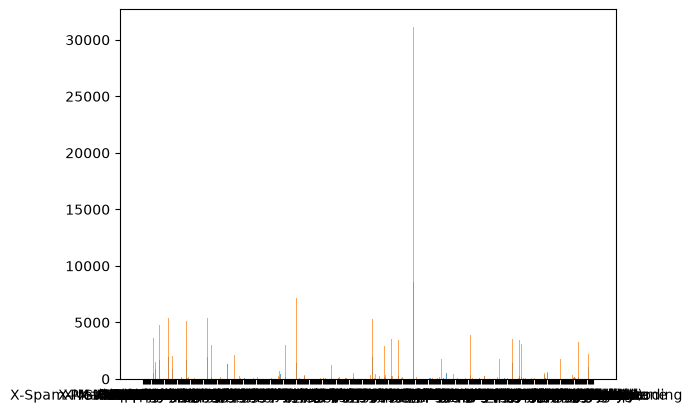

In [ ]:
# WORKING HERE: inspecting if certain headers come more often in one class
from email import policy
from email.parser import BytesParser
from collections import defaultdict

train_folder = Path("./../data_split/train/")

header_counts = {'spam': defaultdict(int), 'ham': defaultdict(int)}
for folder in train_folder.iterdir():
    for idx, filepath in enumerate(folder.iterdir()):        
        with open(filepath, "rb") as f:
            msg = BytesParser(policy=policy.default).parse(f)

        # print(msg)
        for header in msg.keys():
            # if 'x-spam' in header.lower() and not 'x-spamadvice' in header.lower():    
            #     print(f"{header}: {msg[header]}")
            #     print(msg)
            #     raise Exception(f"Found spam header at index {idx}, need to investigate further")
            # if 'spam' in header.lower():
            #     msg.replace_header(header, "HIDDEN")
            #     print(msg)
            if 'ham' in str(folder):
                header_counts['ham'][header] += 1
            else:
                header_counts['spam'][header] += 1
            
        # subject = msg.get("Subject")
        # sender = msg.get("From")

        # print(f"Subject: {subject} \nSender: {sender}\n\n")
        # body_part = msg.get_body(preferencelist=("plain", "html"))

        # print(f"Body part:\n {body_part}\n\n")
        # body = body_part.get_content() if body_part else ""
        # print(f"Body:\n{body}")


        # print(msg)

# here I will plot a clustered bar chart for both classes
import matplotlib.pyplot as plt

headers = list(set(header_counts['spam'].keys()).union(set(header_counts['ham'].keys())))
print(len(headers))

fig, ax = plt.subplots()
ax.bar(headers, [header_counts['spam'][header] for header in headers], label='Spam', alpha=0.7)
ax.bar(headers, [header_counts['ham'][header] for header in headers], label='Ham', alpha=0.7)
plt.show()

# Since there is a lot of headers, we will inspect some of them.

## Modeling

Random Forest is used because tf-idf data is sparse and high dimensional, and random forest is not suitable for this type of data. It is better suited for low-dimensional data.

Also class imbalance should be handled here

taks to do for later:
- model parameters - update the deprecated parameters
- model comparisons -- need to do research on how to find the best model out of the models I have
- class imbalance -- used balanced_accuracy for now, need to do more research
- threshold tuning


these are just ideas as of now to implement later on:
- for selecting the model, we will use cross validation set to evaluate
- the test set will only be used for final evaluation after a model is selected

Here we will do a broad search. Just comparing different models with their default parameters to select top 3 models.

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import SGDClassifier, PassiveAggressiveClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import GridSearchCV

vectorizer = TfidfVectorizer(input='content', lowercase=True, stop_words='english', encoding='latin-1', max_features=10000)

pipeline = Pipeline([
        ('email_cleaner', FunctionTransformer(clean_emails, kw_args={'remove_headers': True})), 
        ('vectorizer', vectorizer),
        ('classifier', LogisticRegression(max_iter=2000))
    ])

paramgrid = [
    { 'classifier': [LogisticRegression(max_iter=2000)]
    },
    { 'classifier': [LinearSVC()],
    },
    { 'classifier': [MultinomialNB()]
    },
    { 'classifier': [ComplementNB()]
    },
    { 'classifier': [SGDClassifier(loss="hinge", random_state=seed)]
    },
    { 'classifier': [SGDClassifier(loss="hinge", penalty = None, learning_rate="pa1", eta0 = 0.1, random_state=seed)],
        # 'classifier': [PassiveAggressiveClassifier(random_state=seed)]
    }
]

grid_search = GridSearchCV(pipeline, paramgrid, cv=5, n_jobs=-1, scoring='balanced_accuracy')
grid_search.fit(X_train, y_train)

score = grid_search.best_estimator_.score(X_test, y_test)
model_params = grid_search.best_params_

print(f"Best model score: {score:.4f}")
print(f"Best parameters: {model_params}")

grid_search_results = pd.DataFrame(grid_search.cv_results_)
grid_search_results.sort_values(by =['rank_test_score'])


Best model score: 0.9907
Best parameters: {'classifier': SGDClassifier(eta0=0.1, learning_rate='pa1', penalty=None, random_state=42)}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_classifier,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
5,1.156632,0.071637,0.174347,0.024707,"SGDClassifier(eta0=0.1, learning_rate='pa1', p...","{'classifier': SGDClassifier(eta0=0.1, learnin...",0.995602,0.990302,0.988918,0.990688,0.989840,0.991070,0.002342,1
4,1.165277,0.038430,0.256506,0.028559,SGDClassifier(random_state=42),{'classifier': SGDClassifier(random_state=42)},0.992056,0.988531,0.987223,0.988993,0.987223,0.988805,0.001771,2
1,1.310160,0.044841,0.248043,0.025945,LinearSVC(),{'classifier': LinearSVC()},0.991204,0.987223,0.986761,0.986375,0.987223,0.987757,0.001753,3
0,1.295322,0.028028,0.293662,0.009162,LogisticRegression(max_iter=2000),{'classifier': LogisticRegression(max_iter=2000)},0.959177,0.966903,0.958352,0.953116,0.964435,0.960397,0.004844,4
3,1.212850,0.038256,0.286408,0.018905,ComplementNB(),{'classifier': ComplementNB()},0.961601,0.944775,0.956768,0.951307,0.959460,0.954782,0.006075,5
2,1.107431,0.039029,0.290975,0.005357,MultinomialNB(),{'classifier': MultinomialNB()},0.941205,0.929293,0.937670,0.923895,0.942208,0.934854,0.007118,6


In [ ]:
from joblib import Memory
cachedir = Memory("./../cache", verbose=0)

pipeline = Pipeline([
        ('email_cleaner', FunctionTransformer(
            clean_emails, 
            kw_args={'remove_headers': True}
        )), 
        ('vectorizer', vectorizer),
        ('classifier', LogisticRegression(max_iter=2000))
    ], memory= cachedir)

paramgrid = [
    { 'classifier': [LinearSVC(random_state=seed, class_weight='balanced', max_iter=100000)], # combination of loss hinge and penalty l1 is not supported
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        'classifier__loss': ["hinge", "squared_hinge"],
        'classifier__penalty': ["l2"],
        'classifier__dual': ['auto', True, False]
    },
    { 'classifier': [LinearSVC(random_state=seed, class_weight='balanced', max_iter=100000)], # combination of loss hinge and penalty l1 is not supported
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        'classifier__loss': ["squared_hinge"],
        'classifier__penalty': ["l1"],
        'classifier__dual': ['auto', True, False]
    },
    { 'classifier': [SGDClassifier(random_state=seed, class_weight='balanced', epsilon=0.0001, max_iter=100000)],
        'classifier__alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
        'classifier__loss': ["hinge", "log", "modified_huber", "squared_hinge"],
        'classifier__penalty': ["l2", "l1", "elasticnet", "None"],
        'classifier__l1_ratio': [0.15, 0.5, 0.85]    
    },
    { 'classifier': [SGDClassifier(loss="hinge", penalty = None, random_state=seed, class_weight='balanced', max_iter=100000)], # passive aggressive classifier
      'classifier__learning_rate': ["pa1", 'pa2'],
      'classifier__eta0': [0.001, 0.01, 0.1, 1, 10, 100]
    }
]


grid_search = GridSearchCV(pipeline, paramgrid, cv=5, n_jobs=-1, scoring='balanced_accuracy')
grid_search.fit(X_train, y_train)

score = grid_search.best_estimator_.score(X_test, y_test)
model_params = grid_search.best_params_

print(f"Best model score: {score:.4f}")
print(f"Best parameters: {model_params}")

grid_search_results = pd.DataFrame(grid_search.cv_results_)
grid_search_results.sort_values(by =['rank_test_score'])

: 

The plan is that in the above cell, we will do some broad search with some default parameters and check how these models do. We will then select top 3/top 2 models from above.

do a hyperparameter search

then threshold tuning => TODO: choose the threshold with the highest precision/recall (check which one flags spam more?)


chat's suggestion:
1. Split data into training and test sets.

2. On training data:
   a. Compare several model families with small searches.
   b. Keep the strongest two or three.
   c. Tune those models more carefully.
   d. Select the best model and hyperparameters.
   e. Generate out-of-fold scores.
   f. Select a threshold based on precision, recall, or business cost.

3. Refit the selected model on all training data.

4. Evaluate the fixed model and fixed threshold once on the test set.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

